In [2]:
import pandas as pd

# Cargar la tabla timesheet desde el directorio de datos.
timesheet = pd.read_csv("../data/timesheet.csv")

# Calcular el promedio de horas y millas registradas por conductor.
promedios_por_conductor = (
    timesheet.groupby("driverId")[["hours-logged", "miles-logged"]]
    .mean()
    .reset_index()
)

promedios_por_conductor

,driverId,hours-logged,miles-logged
0,10,62.153846,2829.807692
1,11,70.038462,3448.076923
2,12,50.750000,2614.653846
3,13,52.442308,2579.346154
4,14,53.480769,2627.384615
5,15,52.576923,2668.269231
6,16,52.807692,2638.557692
7,17,51.942308,2615.230769
8,18,51.038462,2650.653846
9,19,52.653846,2653.230769


In [3]:
# Crear una tabla con el promedio de horas registradas por conductor.
timesheet_with_means = timesheet.copy()
timesheet_with_means["mean_hours-logged"] = (
    timesheet.groupby("driverId")["hours-logged"].transform("mean")
)

timesheet_with_means

,driverId,week,hours-logged,miles-logged,mean_hours-logged
0,10,1,70,3300,62.153846
1,10,2,70,3300,62.153846
2,10,3,60,2800,62.153846
3,10,4,70,3100,62.153846
4,10,5,70,3200,62.153846
...,...,...,...,...,...
1763,43,48,52,2517,52.884615
1764,43,49,56,2743,52.884615
1765,43,50,59,2665,52.884615
1766,43,51,58,2593,52.884615


In [11]:
# Filtrar los registros con horas por debajo del promedio del conductor.
timesheet_below = timesheet_with_means[
    timesheet_with_means["hours-logged"]< timesheet_with_means["mean_hours-logged"]
]

timesheet_below

,driverId,week,hours-logged,miles-logged,mean_hours-logged
2,10,3,60,2800,62.153846
9,10,10,50,2500,62.153846
19,10,20,30,1200,62.153846
20,10,21,50,2500,62.153846
25,10,26,60,2600,62.153846
...,...,...,...,...,...
1756,43,41,51,2701,52.884615
1760,43,45,46,2671,52.884615
1762,43,47,50,2572,52.884615
1763,43,48,52,2517,52.884615


In [13]:
sum_timesheet = timesheet.groupby("driverId")[["hours-logged", "miles-logged"]].sum().reset_index()
sum_timesheet

,driverId,hours-logged,miles-logged
0,10,3232,147150
1,11,3642,179300
2,12,2639,135962
3,13,2727,134126
4,14,2781,136624
5,15,2734,138750
6,16,2746,137205
7,17,2701,135992
8,18,2654,137834
9,19,2738,137968


In [14]:
min_max_timesheet = timesheet.groupby("driverId")["hours-logged"].agg(["min", "max"]).reset_index()

min_max_timesheet

,driverId,min,max
0,10,0,76
1,11,0,92
2,12,0,60
3,13,10,60
4,14,45,60
5,15,45,60
6,16,45,60
7,17,20,60
8,18,45,60
9,19,45,60


In [15]:
drivers = pd.read_csv("../data/drivers.csv")

summary = sum_timesheet.merge(
    drivers[["driverId", "name"]],
    on="driverId",
    how="left",
)

summary

,driverId,hours-logged,miles-logged,name
0,10,3232,147150,George Vetticaden
1,11,3642,179300,Jamie Engesser
2,12,2639,135962,Paul Coddin
3,13,2727,134126,Joe Niemiec
4,14,2781,136624,Adis Cesir
5,15,2734,138750,Rohit Bakshi
6,16,2746,137205,Tom McCuch
7,17,2701,135992,Eric Mizell
8,18,2654,137834,Grant Liu
9,19,2738,137968,Ajay Singh


In [16]:
summary.to_csv("../data/summary.csv", index=False)

In [17]:
top10 = summary.sort_values("miles-logged", ascending=False).head(10)

top10

,driverId,hours-logged,miles-logged,name
1,11,3642,179300,Jamie Engesser
0,10,3232,147150,George Vetticaden
23,33,2759,139285,Sridhara Sabbella
15,25,2723,139180,Jean-Philippe Playe
29,39,2745,138788,David Kaiser
5,15,2734,138750,Rohit Bakshi
25,35,2728,138727,Emil Siemes
11,21,2751,138719,Jeff Markham
31,41,2723,138407,Greg Phillips
19,29,2760,138255,Teddy Choi


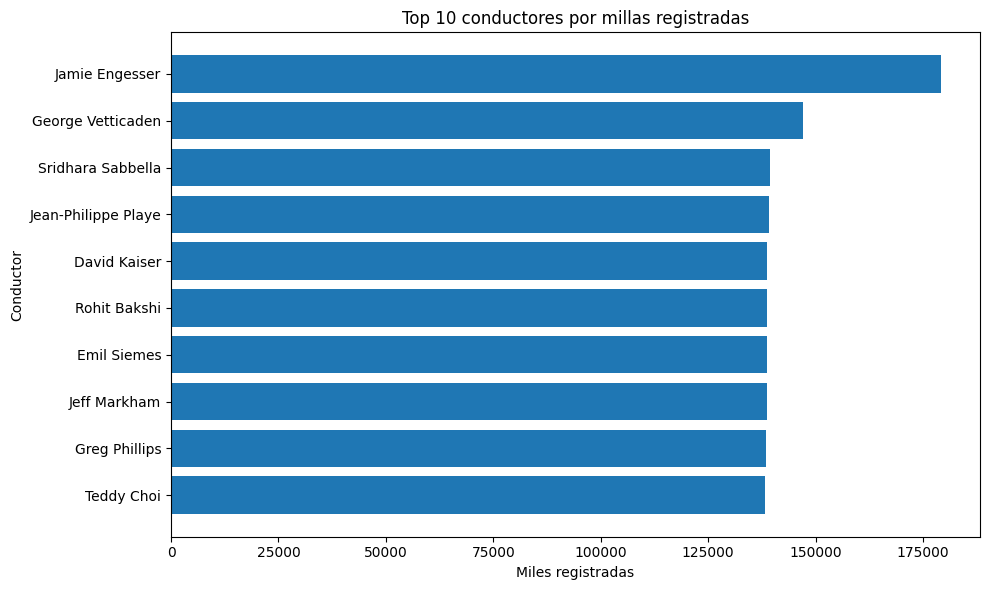

In [20]:
import os

plt.figure(figsize=(10, 6))
plt.barh(top10["name"], top10["miles-logged"])
plt.xlabel("Miles registradas")
plt.ylabel("Conductor")
plt.title("Top 10 conductores por millas registradas")
plt.gca().invert_yaxis()
plt.tight_layout()

os.makedirs("../submission", exist_ok=True)
plt.savefig("../submission/top10_drivers.png", dpi=300, bbox_inches="tight")
plt.show()